# Makisushi sales trend: EDA (rebuilt data, 2026-10-22)

Looks at `datasets/sales.csv` of the REBUILT_SCOPE20 package only (paid lines: `is_revenue` and `net_sales > 0`), September 2021 to September 2026 as one continuous series. The partial last month (2026-09, 8 days) is left out of the monthly charts.

How the series is built, so the charts can be read correctly:
* **2021 is the COVID year** (data starts 2021-09-01): total paid net sales of about PHP 190k for Sep-Dec, with **GrabFood above dine-in**. It is not comparable with later years.
* **2022 is the reopening year**: NCR Alert Level 3 in January, full dine-in capacity from 1 March 2022, so the level climbs month by month until about mid-year.
* **From mid-2022 the level moves around the real level** (Dec 2025 - Aug 2026 is real POS data) with year-specific ups and downs, mild effects of inflation (peak Jan 2023) and typhoon months, random storm / busy days and day-to-day noise. Prices are flat, so inflation acts on volume only.

What to look for: the trend line, whether the yearly level keeps climbing, whether every year repeats the same seasonal shape, and the year-over-year changes.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from statsmodels.tsa.seasonal import STL

# find datasets/sales.csv from wherever the notebook is opened
p = Path.cwd()
while not (p / 'datasets' / 'sales.csv').exists():
    if p.parent == p: raise FileNotFoundError('datasets/sales.csv not found above ' + str(Path.cwd()))
    p = p.parent
SALES = p / 'datasets' / 'sales.csv'

INK, MUTED, GRID = '#1f2933', '#6b7785', '#e4e8ec'
BLUE, ACCENT = '#2b6cb0', '#9aa5b1'                      # one series colour, grey for helper lines
plt.rcParams.update({'figure.dpi': 110, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .8,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
                     'font.size': 9.5, 'legend.frameon': False, 'lines.linewidth': 1.8})
k = FuncFormatter(lambda v, _: f'{v/1000:,.0f}k')

S = pd.read_csv(SALES, parse_dates=['sale_date'])
paid = S[S.is_revenue & (S.net_sales > 0)]
daily = paid.groupby('sale_date').net_sales.sum()                     # open days only (a closed day has no lines)
lastd = daily.index.max()
daily_m = daily[daily.index < pd.Timestamp(lastd.year, lastd.month, 1)]   # drop the partial last month
mon_mean = daily_m.groupby(daily_m.index.to_period('M')).mean()           # net per open day
mon_mean.index = mon_mean.index.to_timestamp()
print(f'{len(S):,} lines, {len(paid):,} paid lines, {daily.index.min().date()} .. {lastd.date()}, {len(daily)} open days')
print(f'monthly points: {len(mon_mean)}')

52,841 lines, 50,588 paid lines, 2021-09-01 .. 2026-09-08, 1812 open days
monthly points: 60


## 1. Monthly net sales per open day, with the trend line
Blue = monthly value. Dark band = 12-month centred average (the trend). Dashed = log-linear fit from July 2022 (after the reopening ramp). Grey band = 2021 COVID year and the reopening months; dotted lines mark events used in the sales plan (Alert Level 1 on 1 Mar 2022, inflation peak Jan 2023, typhoons Carina Jul 2024 and Kristine Oct 2024).

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(mon_mean.index, mon_mean, color=BLUE, marker='o', ms=3.5, label='monthly net per open day')
roll = mon_mean.rolling(12, center=True, min_periods=9).mean()
ax.plot(roll.index, roll, color=INK, lw=2.4, alpha=.55, label='12-month average (trend)')
post = mon_mean['2022-07':]; x = np.arange(len(post)); b = np.polyfit(x, np.log(post.values), 1)
ax.plot(post.index, np.exp(np.polyval(b, x)), color=ACCENT, ls='--', lw=1.6, label=f'log-linear fit from Jul 2022 ({(np.exp(b[0]*12)-1)*100:.1f} %/yr)')
ax.axvspan(mon_mean.index.min(), pd.Timestamp('2022-06-30'), color=GRID, alpha=.6, lw=0)
top = ax.get_ylim()[1]
for d_, t_ in [('2022-03-01', 'Alert Lvl 1'), ('2023-01-01', 'inflation 8.7 %'), ('2024-07-24', 'Carina'), ('2024-10-23', 'Kristine')]:
    ax.axvline(pd.Timestamp(d_), color=MUTED, ls=':', lw=1); ax.text(pd.Timestamp(d_), top * .97, ' ' + t_, color=MUTED, fontsize=8, va='top')
ax.yaxis.set_major_formatter(k); ax.set_ylabel('PHP per open day'); ax.set_title('Monthly net sales per open day'); ax.legend(loc='upper left', ncol=3, bbox_to_anchor=(0, .88))
plt.tight_layout(); plt.show()

## 2. Year-over-year growth by month
Each bar is a month compared with the same month a year earlier (net per open day). The comparison starts in July 2023: before that, a month is measured against the 2021 COVID trough or the 2022 reopening ramp (up to +250 %), and those ratios say nothing about trend.

In [ ]:
yoy = (mon_mean / mon_mean.shift(12) - 1).dropna() * 100
yoy = yoy['2023-07':]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(yoy.index, yoy.values, width=22, color=BLUE)
ax.axhline(0, color=MUTED, lw=1); ax.axhline(yoy.median(), color=ACCENT, ls='--', lw=1.2)
ax.text(yoy.index[1], yoy.max() * .9, f'median {yoy.median():.0f} %', color=MUTED, fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f} %')); ax.set_title('Same month vs a year earlier (net per open day), from Jul 2023')
plt.tight_layout(); plt.show()
print('YoY median:', round(yoy.median(), 1), '% | months with a decline:', int((yoy < 0).sum()), 'of', len(yoy), '| range', round(yoy.min()), '..', round(yoy.max()), '%')
print('by year (mean of the months):', yoy.groupby(yoy.index.year).mean().round(1).to_dict())

## 3. Does every year have the same shape?
Each line is one year, scaled by that year's own monthly average, so only the *shape* across the months is compared. 2021 has September to December only (COVID year), 2022 includes the reopening ramp, and 2026 has January to August only; the correlation is computed for the full normal years 2023-2025.

In [ ]:
m = mon_mean.to_frame('v'); m['y'] = m.index.year; m['mo'] = m.index.month
pv = m.pivot(index='mo', columns='y', values='v'); idx = pv / pv.mean()
yrs = list(idx.columns); ramp = plt.cm.Blues(np.linspace(.3, .95, len(yrs)))        # one hue, light -> dark = older -> newer year
fig, ax = plt.subplots(figsize=(11, 4.6))
for c, y in zip(ramp, yrs):
    lab = {2021: '2021 (Sep-Dec)', 2026: '2026 (Jan-Aug)'}.get(y, str(y))
    ax.plot(idx.index, idx[y], color=c, lw=1.8, marker='o', ms=3, label=lab)
ax.axhline(1, color=MUTED, lw=.8); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list('JFMAMJJASOND'))
ax.set_ylabel('index (year average = 1)'); ax.set_title('Month-of-year shape, one line per year'); ax.legend(ncol=6, loc='upper left')
plt.tight_layout(); plt.show()
off = lambda c: (c.values.sum() - len(c)) / (len(c) * (len(c) - 1))
yy = [y for y in yrs if y in (2023, 2024, 2025)]
print(f'average correlation between full years {yy[0]}-{yy[-1]}: all months {off(idx[yy].corr()):.2f}, Jan-Oct only {off(idx.loc[1:10, yy].corr()):.2f}')

## 4. Heatmap: year x month
Quick view of the same thing. Darker = busier than that year's average.

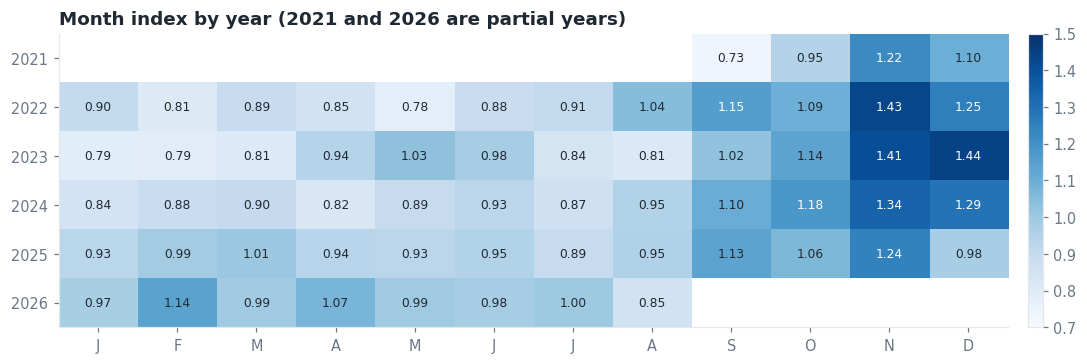

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(idx.T.values, cmap='Blues', aspect='auto', vmin=.7, vmax=1.5)
ax.set_yticks(range(len(idx.columns))); ax.set_yticklabels(idx.columns); ax.set_xticks(range(12)); ax.set_xticklabels(list('JFMAMJJASOND')); ax.grid(False)
for i, y in enumerate(idx.columns):
    for j in range(12):
        v = idx.iloc[j, i]
        if pd.notna(v): ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > 1.15 else INK)
ax.set_title('Month index by year (2021 and 2026 are partial years)'); plt.colorbar(im, ax=ax, fraction=.025, pad=.02); plt.tight_layout(); plt.show()

## 5. Trend / seasonal / residual split (STL)
Splits the monthly series into a slow trend, a repeating yearly part and what is left. A small residual and a stable seasonal part mean the series is easy to learn.

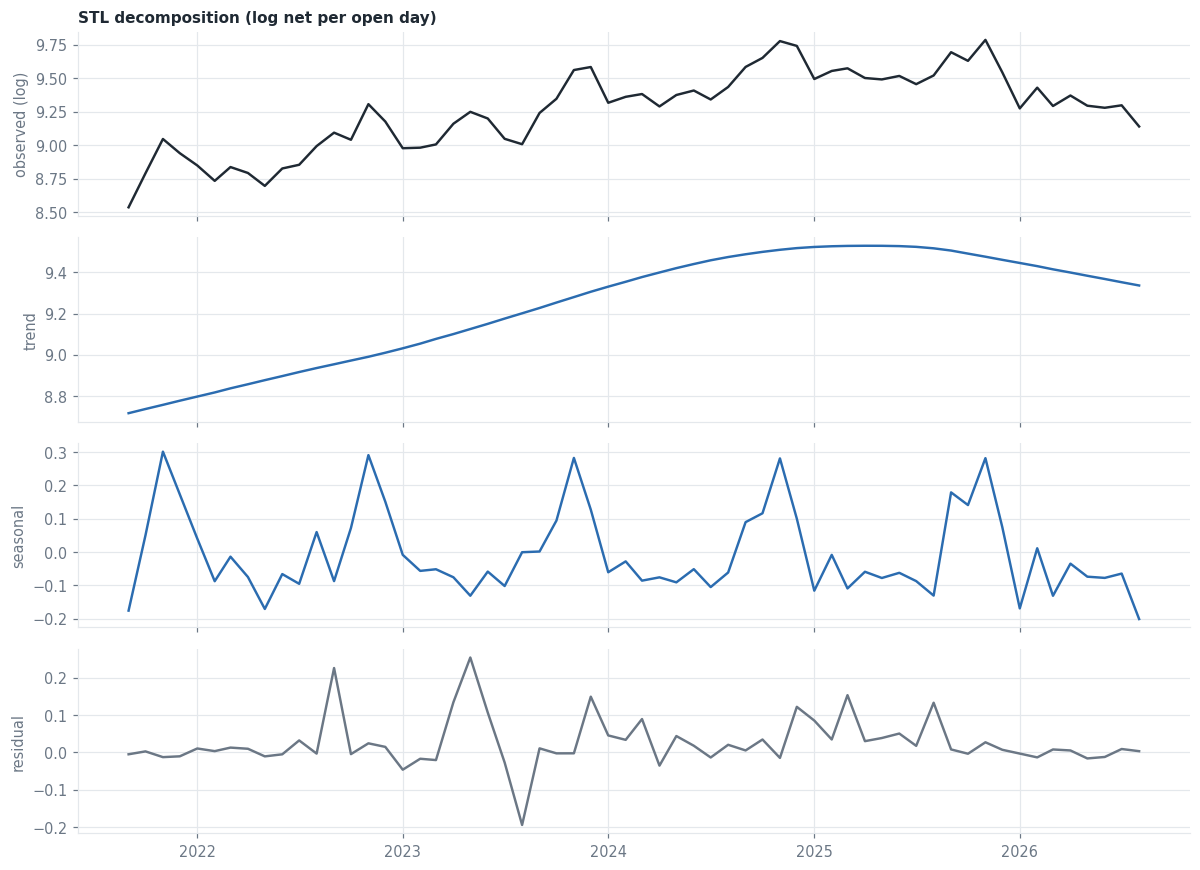

residual SD (log): 0.066 | seasonal amplitude (max-min): 0.5


In [6]:
ser = mon_mean.copy(); ser.index = pd.PeriodIndex(ser.index, freq='M')
res = STL(np.log(ser), period=12, robust=True).fit()
fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for a, (nm, s_, c) in zip(axs, [('observed (log)', res.observed, INK), ('trend', res.trend, BLUE), ('seasonal', res.seasonal, BLUE), ('residual', res.resid, MUTED)]):
    a.plot(s_.index.to_timestamp(), s_.values, color=c, lw=1.6); a.set_ylabel(nm)
axs[0].set_title('STL decomposition (log net per open day)', fontsize=10)
plt.tight_layout(); plt.show()
print('residual SD (log):', round(res.resid.std(), 3), '| seasonal amplitude (max-min):', round(res.seasonal.max() - res.seasonal.min(), 2))

## 6. Daily view with the 28-day average
The noise behind the monthly trend.

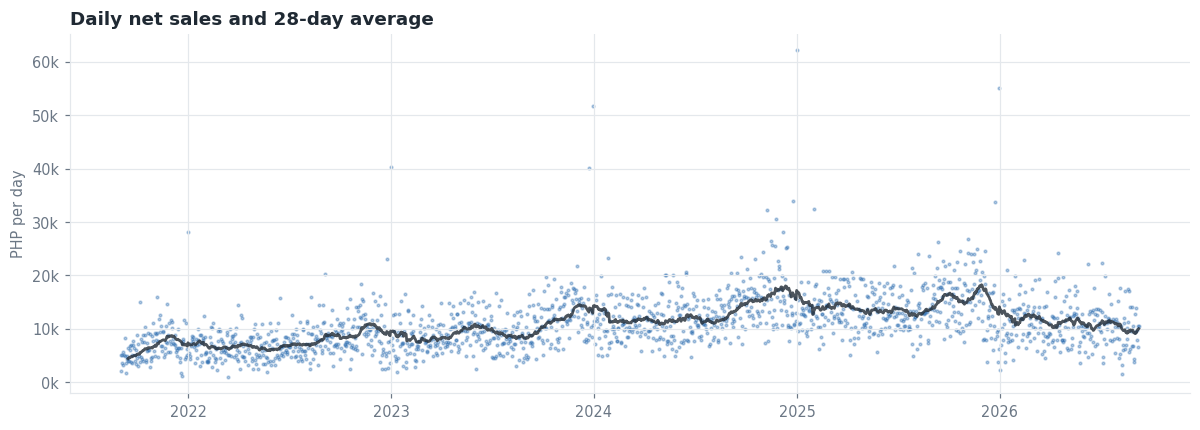

daily CV by year: {2021: 0.49, 2022: 0.47, 2023: 0.45, 2024: 0.4, 2025: 0.35, 2026: 0.37}


In [7]:
d = daily.copy(); r28 = d.rolling(28, min_periods=14).mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(d.index, d, s=3, color=BLUE, alpha=.35); ax.plot(r28.index, r28, color=INK, lw=1.8, alpha=.8)
ax.yaxis.set_major_formatter(k); ax.set_ylabel('PHP per day'); ax.set_title('Daily net sales and 28-day average'); plt.tight_layout(); plt.show()
cv = d.groupby(d.index.year).std() / d.groupby(d.index.year).mean(); print('daily CV by year:', cv.round(2).to_dict())

## 7. Weekday profile

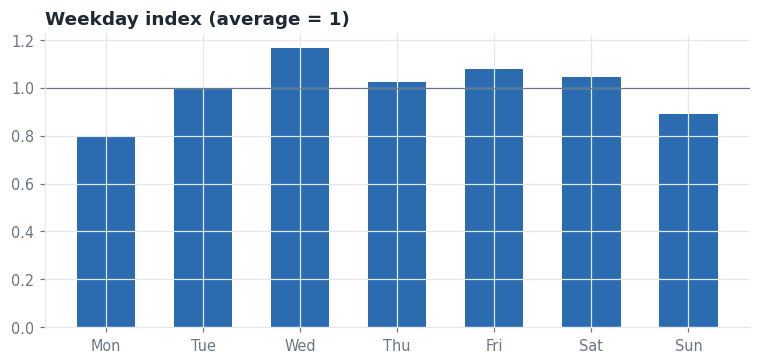

In [8]:
dw = d.to_frame('n'); dw['dow'] = dw.index.dayofweek
prof = dw.groupby('dow').n.mean(); prof = prof / prof.mean()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(7), prof.values, color=BLUE, width=.6)
ax.set_xticks(range(7)); ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); ax.axhline(1, color=MUTED, lw=.8); ax.set_title('Weekday index (average = 1)')
plt.tight_layout(); plt.show()

## 8. Yearly totals
2021 is a partial COVID year (Sep-Dec) and 2022 a reopening year, so their changes are left blank.

In [9]:
yr = daily.groupby(daily.index.year).agg(net_PHP='sum', open_days='count', per_open_day='mean').round(0)
yr['change_in_per_open_day_%'] = (yr.per_open_day.pct_change() * 100).round(1)
yr.loc[[2021, 2022], 'change_in_per_open_day_%'] = np.nan      # 2021 is a partial year (Sep-Dec), so 2022 vs 2021 is not like for like
display(yr)
print('2021 starts in September and 2026 ends on 8 September, so yearly totals are not like for like; per-open-day figures are.')

,net_PHP,open_days,per_open_day,change_in_per_open_day_%
sale_date,,,,
2021,839162.0,121,6935.0,NaN
2022,2782510.0,361,7708.0,NaN
2023,3637901.0,361,10077.0,30.7
2024,4765788.0,362,13165.0,30.6
2025,5158072.0,361,14288.0,8.5
2026,2677293.0,246,10883.0,-23.8


2021 starts in September and 2026 ends on 8 September, so yearly totals are not like for like; per-open-day figures are.


## 9. Is there a yearly upward trend?
The monthly values are divided by a month-of-year index estimated from the full normal years (2023-2025), so what is left is the *level* of each year. The slope is the log-linear fit through the yearly levels, in % a year. 2026 is the real POS period (Jan-Aug).

In [ ]:
# month-of-year index from the full normal years, then the yearly level without seasonality
mm_ = mon_mean.to_frame('v'); mm_['y'] = mm_.index.year; mm_['mo'] = mm_.index.month
full = mm_[mm_.y.isin([2023, 2024, 2025])]; sidx = (full.v / full.groupby('y').v.transform('mean')).groupby(full.mo).mean(); sidx = sidx / sidx.mean()
mm_['lvl'] = mm_.v / mm_.mo.map(sidx)
level = mm_.groupby('y').lvl.mean()
tab = pd.DataFrame({'level_PHP_per_open_day': level.round(0), 'change_%': (level.pct_change() * 100).round(1)})
tab.loc[[2021, 2022], 'change_%'] = np.nan
display(tab)
def slope(a, b_):
    s = level.loc[a:b_]; return (np.exp(np.polyfit(np.arange(len(s)), np.log(s.values), 1)[0]) - 1) * 100
print(f'slope 2022-2025: {slope(2022, 2025):.1f} %/yr | 2023-2025: {slope(2023, 2025):.1f} %/yr | 2023-2026 (with the real months): {slope(2023, 2026):.1f} %/yr')
chg = level.pct_change().loc[2023:] * 100
print('direction of the yearly changes from 2023:', ' '.join(f'{y}: {v:+.0f} %' for y, v in chg.items()), '->', 'not a one-way climb' if (chg > 0).any() and (chg < 0).any() else 'one-way')
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = [MUTED if y in (2021, 2022) else BLUE for y in level.index]; ax.bar([str(y) for y in level.index], level.values, color=cols, width=.6)
for i, v in enumerate(level.values): ax.text(i, v, f'{v/1000:.1f}k', ha='center', va='bottom', fontsize=9, color=INK)
ax.yaxis.set_major_formatter(k); ax.set_title('Yearly level (net per open day, seasonality removed)'); ax.set_ylabel('PHP per open day'); plt.tight_layout(); plt.show()

## 10. Same months in every year (Jan-Aug)
A fair trend test: the same eight months of every year, so seasonality cannot fake or hide a trend. 2026 is the real POS period. The generated years 2023-2025 are set to the real Jan-Aug 2026 level plus or minus a few percent, in no particular direction; 2022 is the reopening year.

In [ ]:
ja = {y: mon_mean[(mon_mean.index.year == y) & (mon_mean.index.month <= 8)].mean() for y in range(2022, 2027)}
ja = pd.Series(ja); vs = (ja / ja[2026] - 1) * 100
tab2 = pd.DataFrame({'Jan-Aug mean PHP per open day': ja.round(0), 'vs real 2026 %': vs.round(1)}); display(tab2)
g3 = ja.loc[2023:2025]; sl3 = (np.exp(np.polyfit(np.arange(3), np.log(g3.values), 1)[0]) - 1) * 100
print(f'2023-2025 slope: {sl3:+.1f} %/yr | spread between the three years: {(g3.max() / g3.min() - 1) * 100:.1f} % | direction: {" ".join(f"{y}: {v:+.1f} %" for y, v in (g3.pct_change().dropna() * 100).items())}')
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = [MUTED, BLUE, BLUE, BLUE, INK]; ax.bar([str(y) for y in ja.index], ja.values, color=cols, width=.6)
for i, v in enumerate(ja.values): ax.text(i, v, f'{v/1000:.1f}k', ha='center', va='bottom', fontsize=9, color=INK)
ax.axhline(ja[2026], color=ACCENT, ls='--', lw=1.2); ax.yaxis.set_major_formatter(k); ax.set_title('Jan-Aug net per open day (dashed = real 2026)'); ax.set_ylabel('PHP per open day'); plt.tight_layout(); plt.show()

## 11. Channel mix by year and by month
GrabFood against dine-in, share of paid net sales. In 2021 (COVID restrictions) GrabFood is the larger channel. In 2022 it stays high and then fades gently month by month through 2023 and 2024, and is steady from 2024 at a few percent, close to the real 2026 share.

In [ ]:
ch = paid.groupby([paid.sale_date.dt.year, 'channel']).net_sales.sum().unstack().fillna(0)
share = ch.div(ch.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar([str(y) for y in share.index], share['GrabFood'], color=BLUE, width=.6, label='GrabFood')
ax.bar([str(y) for y in share.index], share['Dine-In'], bottom=share['GrabFood'], color=GRID, width=.6, label='Dine-In')
for i, v in enumerate(share['GrabFood']): ax.text(i, v / 2, f'{v:.0f} %', ha='center', va='center', fontsize=9, color='white' if v > 15 else INK)
ax.set_ylabel('% of paid net sales'); ax.set_title('Channel mix by year'); ax.legend(ncol=2, loc='lower right', bbox_to_anchor=(1, 1.0)); plt.tight_layout(); plt.show()
y21 = ch.loc[2021]; print(f"2021: GrabFood PHP {y21['GrabFood']:,.0f} vs Dine-In PHP {y21['Dine-In']:,.0f} -> GrabFood greater: {y21['GrabFood'] > y21['Dine-In']}; 2021 total PHP {y21.sum():,.0f}")

In [ ]:
# GrabFood trend, September 2021 - August 2026: monthly sales against dine-in (top) and the share of net sales (bottom)
ch_m = paid.groupby([paid.sale_date.dt.to_period('M'), 'channel']).net_sales.sum().unstack().fillna(0)
cut = pd.Period(f'{lastd.year}-{lastd.month:02d}')                       # drop the partial last month
ch_m = ch_m[ch_m.index < cut]; ch_m.index = ch_m.index.to_timestamp()
sh = ch_m['GrabFood'] / ch_m.sum(axis=1) * 100
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={'height_ratios': [1.1, 1]})
a1.plot(ch_m.index, ch_m['GrabFood'], color=BLUE, marker='o', ms=3.5, label='GrabFood net sales')
a1.plot(ch_m.index, ch_m['Dine-In'], color=ACCENT, lw=1.6, label='Dine-In net sales')
a1.yaxis.set_major_formatter(k); a1.set_ylabel('PHP per month'); a1.legend(loc='upper left', ncol=2); a1.set_title('GrabFood trend, Sep 2021 - Aug 2026')
a2.plot(sh.index, sh.values, color=BLUE, marker='o', ms=3.5); a2.fill_between(sh.index, sh.values, color=BLUE, alpha=.12); a2.axhline(50, color=ACCENT, ls='--', lw=1)
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f} %')); a2.set_ylabel('GrabFood share of net sales (dashed = equal to dine-in)')
for a in (a1, a2): a.axvline(pd.Timestamp('2022-03-01'), color=MUTED, ls=':', lw=1)
a2.text(pd.Timestamp('2022-03-10'), 60, 'full dine-in capacity (1 Mar 2022)', color=MUTED, fontsize=8)
plt.tight_layout(); plt.show()
yr_g = pd.DataFrame({'GrabFood net PHP': ch['GrabFood'].round(0), 'GrabFood share %': (ch['GrabFood'] / ch.sum(axis=1) * 100).round(1),
                     'GrabFood lines': paid[paid.channel == 'GrabFood'].groupby(paid.sale_date.dt.year).size(), 'Dine-In net PHP': ch['Dine-In'].round(0)})
display(yr_g)
print('GrabFood share (%) in January and July:', {str(i.date())[:7]: round(v, 1) for i, v in sh.items() if i.month in (1, 7)})

## Reading
* **There is no yearly upward trend.** The generated years 2023-2025 sit at the same level as the real 2026 months (section 10: within about 1 %, slope close to zero), with ups and downs only from noise, storm days and the seasonal pattern.
* The one big rise is 2021 to 2022: it is the end of the COVID restrictions (reopening), not organic growth. 2021 is a depressed year of about PHP 190k in total, with GrabFood above dine-in.
* GrabFood is large in 2022 and fades gently to a steady few percent from 2024 (section 11).
* Sections 3-7 (shape, STL, daily, weekday) describe the noise and the seasonality on top of that level.